In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from transformers import (
    AutoImageProcessor,
    ResNetForImageClassification
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
# Chuẩn bị dữ liệu VinaFood21
MODEL_NAME = "microsoft/resnet-50"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

print(processor)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

ConvNextImageProcessor {
  "crop_pct": 0.875,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "ConvNextImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}



In [4]:
mean = processor.image_mean
std = processor.image_std

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [5]:
# Thay bằng đường dẫn dữ liệu thực tế trên máy
import glob, zipfile

zips = glob.glob("/kaggle/input/VinaFood21/VinaFood21.zip", recursive=True)
if zips:
    EXTRACT_DIR = "/kaggle/working/VinaFood21"
    if not os.path.exists(EXTRACT_DIR):
        with zipfile.ZipFile(zips[0]) as zf:
            zf.extractall(EXTRACT_DIR)
else:
    # Kaggle đã tự giải nén sẵn
    EXTRACT_DIR = "/kaggle/input"

DATA_DIR = EXTRACT_DIR
for root, dirs, _ in os.walk(EXTRACT_DIR):
    if "train" in dirs:
        DATA_DIR = root
        break
print("DATA_DIR:", DATA_DIR, os.listdir(DATA_DIR))

train_folder = os.path.join(DATA_DIR, "train")
val_folder = os.path.join(DATA_DIR, "val")
if not os.path.exists(val_folder):
    val_folder = os.path.join(DATA_DIR, "test")

full_train_aug = datasets.ImageFolder(
    train_folder,
    transform=train_transform
)

full_train_eval = datasets.ImageFolder(
    train_folder,
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    val_folder,
    transform=eval_transform
)

assert len(full_train_aug.classes) == 21
assert full_train_aug.class_to_idx == full_train_eval.class_to_idx
assert full_train_aug.class_to_idx == test_ds.class_to_idx

classes = full_train_aug.classes

n_train = int(0.9 * len(full_train_aug))

generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(full_train_aug),
    generator=generator
).tolist()

train_indices = indices[:n_train]
val_indices = indices[n_train:]

train_ds = Subset(full_train_aug, train_indices)
val_ds = Subset(full_train_eval, val_indices)

train_dl = DataLoader(
    train_ds,
    batch_size=16,
    shuffle=True
)

val_dl = DataLoader(
    val_ds,
    batch_size=16,
    shuffle=False
)

test_dl = DataLoader(
    test_ds,
    batch_size=16,
    shuffle=False
)

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("Classes:", classes)

DATA_DIR: /kaggle/input/datasets/ttrinh1805/vinafood21/VinaFood21 ['README.txt', 'test', 'train']
Train: 9039
Validation: 1005
Test: 6682
Classes: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


In [6]:
# Load Pretrained ResNet50 và thay classifier
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = ResNetForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=21,
    ignore_mismatched_sizes=True,
    id2label={i: name for i, name in enumerate(classes)},
    label2id={name: i for i, name in enumerate(classes)}
)

model = model.to(device)

print(model)

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

[transformers] You passed `num_labels=21` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-50
Key                 | Status   |                                                                                             
--------------------+----------+---------------------------------------------------------------------------------------------
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([21])            
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 2048]) vs model:torch.Size([21, 2048])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ResNetForImageClassification(
  (resnet): ResNetModel(
    (embedder): ResNetEmbeddings(
      (embedder): ResNetConvLayer(
        (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (activation): ReLU()
      )
      (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (encoder): ResNetEncoder(
      (stages): ModuleList(
        (0): ResNetStage(
          (layers): Sequential(
            (0): ResNetBottleNeckLayer(
              (shortcut): ResNetShortCut(
                (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (normalization): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              )
              (layer): Sequential(
                (0): ResNetConvLayer(
                  (convolution): Conv2d(64

In [7]:
model.eval()

with torch.no_grad():
    x = torch.randn(2, 3, 224, 224).to(device)

    outputs = model(pixel_values=x)

    print("Output shape:", outputs.logits.shape)

Output shape: torch.Size([2, 21])


In [8]:
# Khởi tạo Adam Optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

EPOCHS = 10

In [9]:
# Hàm training
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)
        logits = outputs.logits

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [10]:
# Hàm Validation
@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(pixel_values=images)
        logits = outputs.logits

        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [11]:
# Finetuning Loop
train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )

    val_loss, val_acc = validate(
        model, val_dl, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_pretrained_resnet50.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/10] | Train Loss: 2.4753 | Train Acc: 0.2822 | Val Loss: 1.5194 | Val Acc: 0.5871
Epoch [2/10] | Train Loss: 1.1737 | Train Acc: 0.6735 | Val Loss: 0.7362 | Val Acc: 0.7751
Epoch [3/10] | Train Loss: 0.7441 | Train Acc: 0.7753 | Val Loss: 0.5698 | Val Acc: 0.8219
Epoch [4/10] | Train Loss: 0.5553 | Train Acc: 0.8327 | Val Loss: 0.4983 | Val Acc: 0.8428
Epoch [5/10] | Train Loss: 0.4431 | Train Acc: 0.8616 | Val Loss: 0.4360 | Val Acc: 0.8607
Epoch [6/10] | Train Loss: 0.3623 | Train Acc: 0.8901 | Val Loss: 0.4300 | Val Acc: 0.8627
Epoch [7/10] | Train Loss: 0.2946 | Train Acc: 0.9108 | Val Loss: 0.3988 | Val Acc: 0.8726
Epoch [8/10] | Train Loss: 0.2535 | Train Acc: 0.9239 | Val Loss: 0.3983 | Val Acc: 0.8776
Epoch [9/10] | Train Loss: 0.2217 | Train Acc: 0.9326 | Val Loss: 0.3964 | Val Acc: 0.8726
Epoch [10/10] | Train Loss: 0.1730 | Train Acc: 0.9480 | Val Loss: 0.3749 | Val Acc: 0.8796


In [12]:
# Đánh giá Accuracy, Precision, Recall và F1-macro
model.load_state_dict(
    torch.load(
        "best_pretrained_resnet50.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_dl:
        images = images.to(device)

        logits = model(pixel_values=images).logits
        preds = logits.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-macro:  {f1:.4f}")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(21)),
    target_names=classes,
    zero_division=0
))

Accuracy:  0.8520
Precision: 0.8507
Recall:    0.8494
F1-macro:  0.8481
                  precision    recall  f1-score   support

        banh-can       0.89      0.91      0.90       241
        banh-hoi       0.90      0.85      0.87       607
    banh-mi-chao       0.86      0.94      0.90       289
        banh-tet       0.93      0.86      0.90       364
 banh-trang-tron       0.88      0.91      0.89       309
          banh-u       0.82      0.86      0.84       176
        banh-uot       0.78      0.81      0.80       560
       bap-nuong       0.95      0.98      0.96       143
          bo-kho       0.74      0.80      0.77       338
       bo-la-lot       0.88      0.95      0.91       458
       bot-chien       0.83      0.86      0.84       276
           ca-ri       0.68      0.43      0.53       171
    canh-kho-qua       0.90      0.92      0.91       290
   canh-khoai-mo       0.96      0.91      0.94       198
        ga-nuong       0.82      0.81      0.82       372

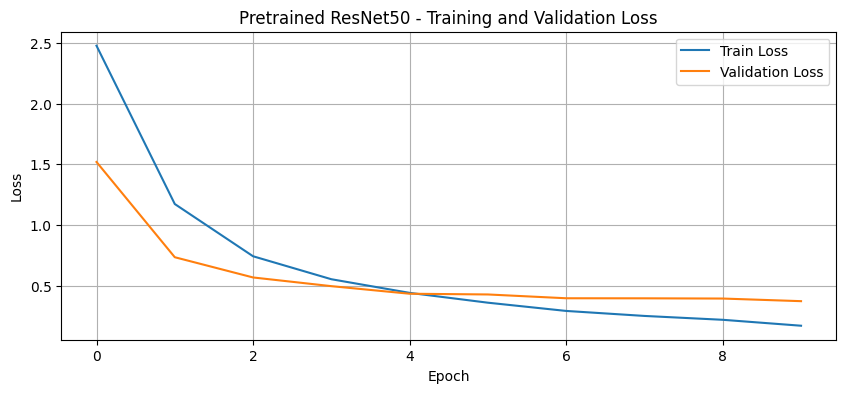

In [13]:
plt.figure(figsize=(10, 4))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pretrained ResNet50 - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

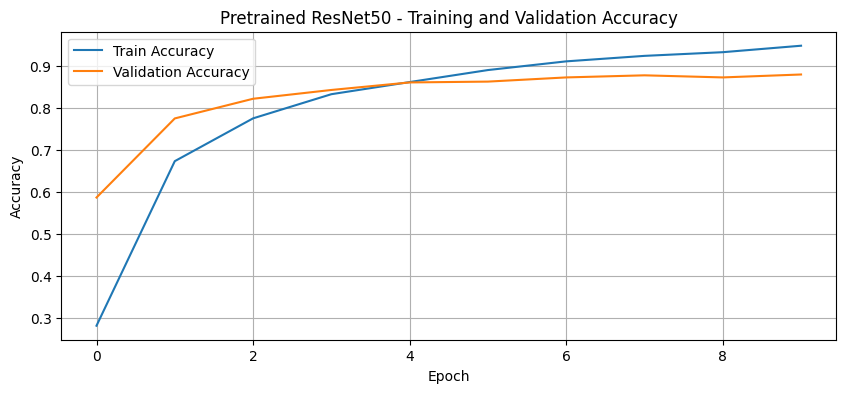

In [14]:
plt.figure(figsize=(10, 4))

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Pretrained ResNet50 - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

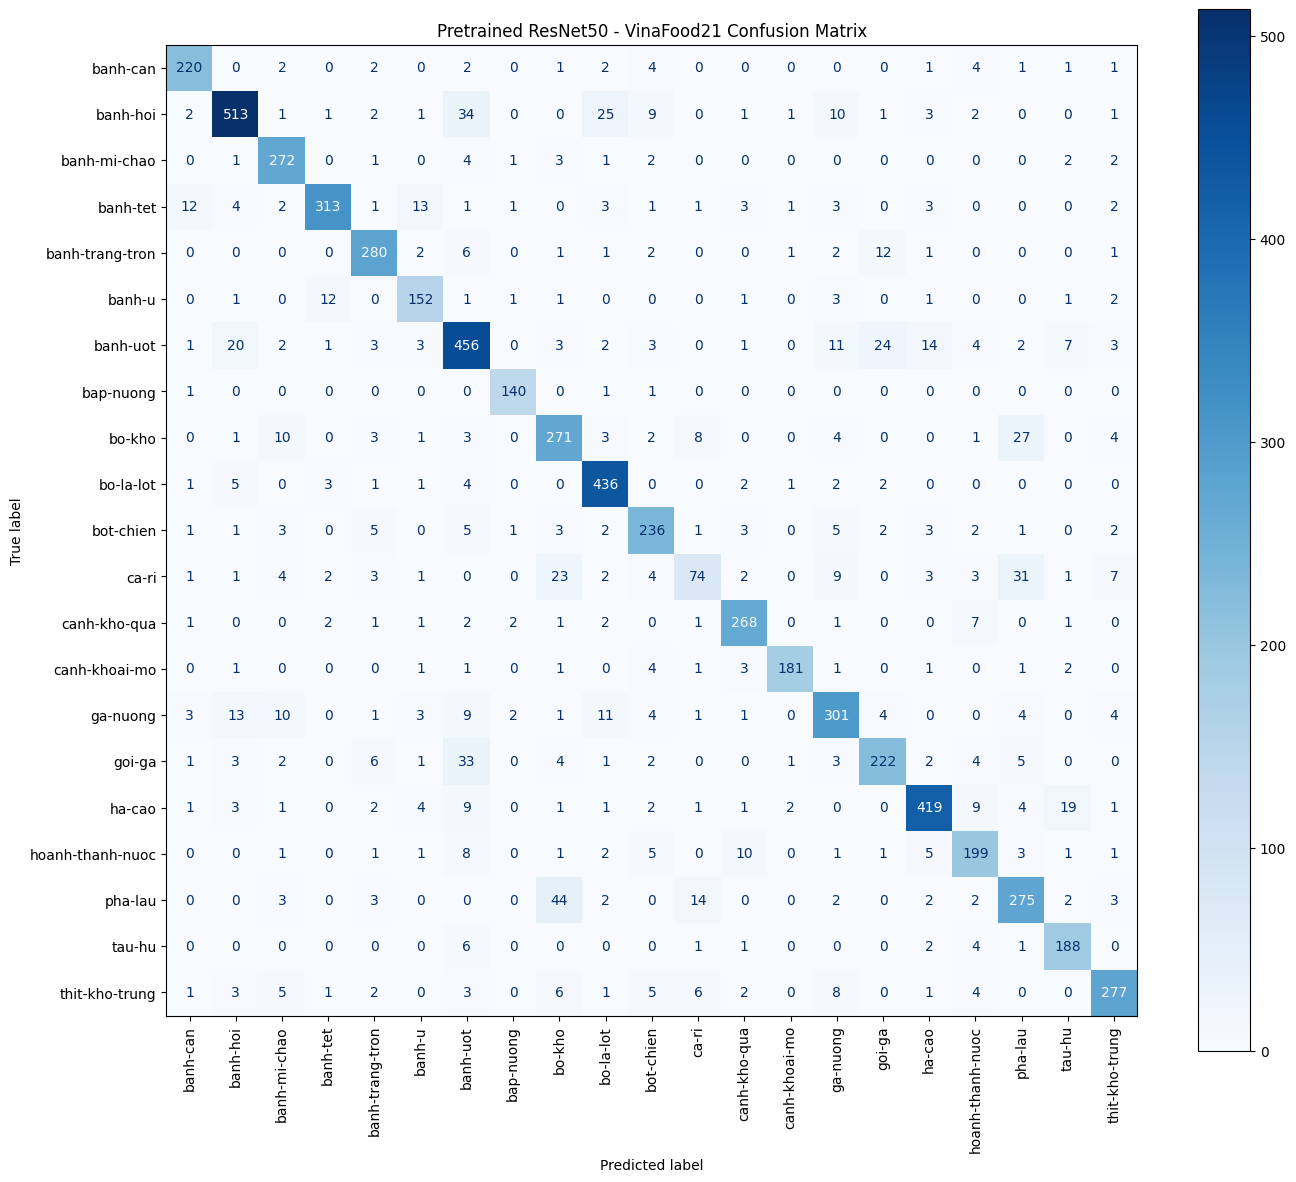

In [15]:
fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(21)),
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=90,
    ax=ax
)

plt.title("Pretrained ResNet50 - VinaFood21 Confusion Matrix")
plt.tight_layout()
plt.show()